# Исторические покупки с предполагаемыми касаниями

Первый этап — генерация данных и описание выборки. Измените параметры следующей ячейки и выполните **Restart Kernel → Run All**. Ноутбук запускается из корня репозитория или папки notebooks, нужны pandas, numpy и matplotlib.

Все исторические покупки, курсы и суммы сохраняются. Касания, заявки и непокупающая аудитория вымышлены. Публикации берутся из исторической разметки. Пост выбирается равновероятно среди доступных по времени, без предпочтений по категории или курсу. Наличие касания не подтверждает влияние поста на покупку.

Суммы затрат неизвестны. Распределение выручки и ROMI на этом этапе не рассчитываются. Выходные таблицы составляют самостоятельную экспериментальную базу данных в CSV.

In [1]:
# ГЛОБАЛЬНЫЕ ПАРАМЕТРЫ — изменяйте здесь
SEED = 42
CONTRACT_VERSION = '1.4'
BUYER_TOUCH_COUNTS = [0, 1, 2, 3]
BUYER_TOUCH_PROBABILITIES = [0.30, 0.35, 0.25, 0.10]
ATTRIBUTION_WINDOW_DAYS = 30
BUYER_DELAY_SCALE_DAYS = 7.0
NONBUYERS_PER_BUYER = 3.0
NONBUYER_EXTRA_TOUCHES_LAMBDA = 1.0  # число касаний = 1 + Poisson(lambda)
POST_ATTENTION_HALF_LIFE_DAYS = 7.0  # None — без угасания; иначе > 0
NONBUYER_TIME_DISTRIBUTION = 'uniform'  # время касания внутри доступного периода
# NONBUYER_DELAY_SCALE_DAYS удалён: сначала выбирается время, затем пост
#
LEAD_PROBABILITY = 0.20  # вероятность заявки после каждого касания в обеих группах
TIMEZONE = 'Europe/Moscow'  # исходные времена считаем московскими
MIN_GAP_SECONDS = 1  # строго после публикации/предыдущей покупки и до оплаты
OUTPUT_SUBDIR = 'outputs/experiments/history_enrichment'

### Категории покупки
`has_generated_touches` — есть сгенерированные касания; `no_generated_touches` — их нет. Причина отсутствия хранится отдельно: ноль по распределению, нет подходящих публикаций или нет допустимого временного интервала. Исторический источник всех покупок остаётся неизвестным (`historical_source=unknown`).


## Правила генерации

Число касаний покупки задаёт BUYER_TOUCH_COUNTS / BUYER_TOUCH_PROBABILITIES. Сначала выбирается время касания: усечённая экспонента назад от покупки с параметром BUYER_DELAY_SCALE_DAYS. Интервал ограничен началом наблюдения, окном атрибуции, предыдущей покупкой и наличием хотя бы одного опубликованного поста. Затем выбирается пост, опубликованный минимум MIN_GAP_SECONDS назад.

Вес выбора поста: `2 ** (-возраст_поста_в_днях / POST_ATTENTION_HALF_LIFE_DAYS)`, нормированный среди доступных постов. Возраст считается в момент касания. Значение 7 означает двукратное снижение веса за неделю; None отключает угасание. Это предположение, не оценка из истории. Касания одного поста могут повторяться. Категории и курс не влияют на выбор.

Для непокупателя генерируется 1 + Poisson(lambda) касаний. Время каждого равномерно в текущем периоде после первой публикации; затем пост выбирается с тем же угасанием. Прежняя задержка от выбранного поста больше не задаётся: порядок выбора теперь «время → пост». Это отдельное явное предположение о времени неоплаченных касаний.

Заявка создаётся после касания с вероятностью LEAD_PROBABILITY. Её время равномерно между касанием и покупкой / концом периода. С покупкой связывается последняя созданная для неё заявка, другие остаются без оплаты.

Предыстории нет. Если подходящих публикаций/интервала нет, запрошенные касания теряются с отдельной причиной. Отсутствие касаний не устанавливает органический источник. Исторические покупки и суммы не меняются.


In [2]:
from pathlib import Path
from decimal import Decimal
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data/raw/base.csv').exists())
OUTPUT = ROOT / OUTPUT_SUBDIR
OUTPUT.mkdir(parents=True, exist_ok=True)

assert len(BUYER_TOUCH_COUNTS) == len(BUYER_TOUCH_PROBABILITIES) > 0
assert all(isinstance(v, int) and v >= 0 for v in BUYER_TOUCH_COUNTS)
assert len(set(BUYER_TOUCH_COUNTS)) == len(BUYER_TOUCH_COUNTS)
assert all(np.isfinite(v) and v >= 0 for v in BUYER_TOUCH_PROBABILITIES)
assert np.isclose(sum(BUYER_TOUCH_PROBABILITIES), 1)
assert all(np.isfinite(v) and v > 0 for v in [ATTRIBUTION_WINDOW_DAYS, BUYER_DELAY_SCALE_DAYS, MIN_GAP_SECONDS])
assert np.isfinite(NONBUYERS_PER_BUYER) and NONBUYERS_PER_BUYER >= 0
assert np.isfinite(NONBUYER_EXTRA_TOUCHES_LAMBDA) and NONBUYER_EXTRA_TOUCHES_LAMBDA >= 0
assert 0 <= LEAD_PROBABILITY <= 1

# Независимые потоки случайности для числа касаний, времени и заявок.
streams = np.random.SeedSequence(SEED).spawn(4)
count_rng, buyer_rng, nonbuyer_rng, lead_rng = [np.random.default_rng(s) for s in streams]
assert POST_ATTENTION_HALF_LIFE_DAYS is None or (np.isfinite(POST_ATTENTION_HALF_LIFE_DAYS) and POST_ATTENTION_HALF_LIFE_DAYS > 0)
assert NONBUYER_TIME_DISTRIBUTION == "uniform"


## Подготовка истории без потери сумм

Один заказ определяется студентом и точным временем. Исходная строка становится позицией заказа, её сумма сохраняется до копейки. Совпадающие строки не удаляются без доказательства дубля. Покупателям присваиваются экспериментальные ID; связь между повторными покупками сохраняется.

При некорректных обязательных полях выполнение останавливается. Разметка категорий и продуктов постов наследуется из EDA и может содержать ошибки. История содержит публикации собственного канала, а не полный перечень оплаченной рекламы.

In [3]:
sales_path = ROOT / 'data/raw/base.csv'
posts_path = ROOT / 'data/processed/analysis_posts_v2.csv'
raw = pd.read_csv(sales_path, dtype=str)
assert raw.notna().all().all(), 'В исходных продажах есть пропуски'
sales = raw.rename(columns={'Номер студента': 'student_id', 'Сумма': 'raw_amount', 'Курс': 'course', 'Время': 'raw_time'}).copy()
sales['timestamp'] = pd.to_datetime(sales.raw_time, format='%d.%m.%Y %H:%M:%S', errors='raise').dt.tz_localize(TIMEZONE)

def to_cents(value):
    amount = Decimal(''.join(value.split()).replace(',', '.'))
    assert amount.is_finite() and amount >= 0 and amount * 100 == (amount * 100).to_integral_value()
    return int(amount * 100)

sales['amount_cents'] = sales.raw_amount.map(to_cents)
student_ids = sorted(sales.student_id.unique())
user_map = {student: f'history_user_{i+1}' for i, student in enumerate(student_ids)}
sales['user_id_hash'] = sales.student_id.map(user_map)
orders = sales.groupby(['user_id_hash', 'timestamp'], as_index=False).amount_cents.sum().sort_values(['user_id_hash', 'timestamp']).reset_index(drop=True)
orders['order_id'] = [f'history_order_{i+1}' for i in range(len(orders))]
orders['amount'] = orders.amount_cents / 100
orders['previous_order_time'] = orders.groupby('user_id_hash').timestamp.shift()
orders['record_origin'] = 'historical_purchase'
orders['lead_id'] = pd.Series(pd.NA, index=orders.index, dtype='Int64')
order_keys = orders.set_index(['user_id_hash', 'timestamp']).order_id
source_keys = pd.MultiIndex.from_frame(sales[['user_id_hash', 'timestamp']])
assert order_keys.index.is_unique and source_keys.isin(order_keys.index).all()
items = sales.copy()
items['order_id'] = order_keys.reindex(source_keys).to_numpy()
items = items[['order_id', 'course', 'amount_cents']].copy()
items.insert(0, 'item_id', np.arange(1, len(items)+1))
items['amount'] = items.amount_cents / 100
items['record_origin'] = 'historical_purchase_item'

posts = pd.read_csv(posts_path)
assert posts.post_id.notna().all() and posts.post_id.is_unique
posts['publication_time'] = pd.to_datetime(posts.event_timestamp, errors='raise').dt.tz_localize(TIMEZONE)
posts['placement_id'] = 'history_post_' + posts.post_id.astype(str)
posts = posts.sort_values(['publication_time', 'placement_id']).reset_index(drop=True)
posts['record_origin'] = 'historical_post_with_eda_labels'
posts['cost'] = np.nan
posts['cost_known'] = False
observation_start = orders.timestamp.min().normalize()
observation_end = orders.timestamp.max().normalize() + pd.Timedelta(days=1)
period_days = (observation_end - observation_start).days
print(f'{len(orders)} заказов, {len(student_ids)} покупателей, {len(items)} позиций, {items.course.nunique()} курсов')
print(f'Выручка {orders.amount.sum():,.2f} ₽; {period_days} дней; {len(posts)} публикаций')

628 заказов, 606 покупателей, 795 позиций, 18 курсов
Выручка 5,904,671.67 ₽; 38 дней; 48 публикаций


## Генерация касаний и заявок

В touches поле generation_order_id фиксирует, для какой покупки создано касание. Это служебное поле генерации. В дальнейшем движок атрибуции должен самостоятельно выбирать касания по пользователю и времени.

При изменении параметров меняются только сгенерированные данные. Покупки и позиции проверяются на точное совпадение с источником.

In [4]:
gap = pd.Timedelta(seconds=MIN_GAP_SECONDS)
window = pd.Timedelta(days=ATTRIBUTION_WINDOW_DAYS)
touch_rows, order_diagnostics = [], []


def truncated_exponential(rng, lower, upper, scale):
    # Условная экспонента на [lower, upper], без rejection sampling и clipping.
    assert 0 <= lower < upper
    mass = -np.expm1(-(upper-lower)/scale)
    return lower - scale * np.log1p(-rng.random() * mass)


def post_probabilities(ages_days, half_life):
    ages = np.asarray(ages_days, dtype=float)
    assert len(ages) and np.isfinite(ages).all() and (ages >= 0).all()
    if half_life is None:
        return np.full(len(ages), 1/len(ages))
    assert np.isfinite(half_life) and half_life > 0
    # Вычитание минимального возраста предотвращает обнуление всех весов.
    weights = np.exp2(-(ages-ages.min())/half_life)
    return weights/weights.sum()

def choose_post(rng, touch_time):
    available = posts.loc[posts.publication_time.add(gap).le(touch_time)]
    assert len(available), 'Нет опубликованных постов в момент касания'
    age = (touch_time-available.publication_time).dt.total_seconds()/86400
    probabilities = post_probabilities(age, POST_ATTENTION_HALF_LIFE_DAYS)
    return available.iloc[int(rng.choice(len(available), p=probabilities))]

# Независимые проверки формулы, одинаковых возрастов и отключения угасания.
assert np.allclose(post_probabilities([0,7,14],7), np.array([4,2,1])/7)
assert np.allclose(post_probabilities([2,2],7), [.5,.5])
assert np.allclose(post_probabilities([0,7,14],None), np.ones(3)/3)
assert np.isclose(post_probabilities([10000,10007],7).sum(),1)
first_post_time = posts.publication_time.min()+gap
for order in orders.itertuples():
    requested = int(count_rng.choice(BUYER_TOUCH_COUNTS, p=BUYER_TOUCH_PROBABILITIES))
    start = max(observation_start, order.timestamp-window)
    if pd.notna(order.previous_order_time):
        start = max(start, order.previous_order_time+gap)
    end = order.timestamp-gap
    candidates = posts.loc[posts.publication_time.add(gap).lt(end)]
    reason = None
    if requested == 0:
        reason = 'sampled_zero'
    elif start >= end:
        reason = 'no_valid_interval'
    elif candidates.empty:
        reason = 'no_available_posts'
    actual = requested if reason is None else 0
    category = 'has_generated_touches' if actual else 'no_generated_touches'
    order_diagnostics.append((order.order_id,requested,actual,len(candidates),category,reason))
    for _ in range(actual):
        earliest = max(start, first_post_time)
        delay_min = gap.total_seconds()/86400
        delay_max = (order.timestamp-earliest).total_seconds()/86400
        delay = truncated_exponential(buyer_rng,delay_min,delay_max,BUYER_DELAY_SCALE_DAYS)
        touch_time = order.timestamp-pd.Timedelta(days=delay)
        post = choose_post(buyer_rng,touch_time)
        touch_rows.append((len(touch_rows)+1,order.user_id_hash,post.placement_id,touch_time,order.order_id,'buyer'))

n_nonbuyers = int(round(len(student_ids)*NONBUYERS_PER_BUYER))
nonbuyer_ids = [f'synthetic_nonbuyer_{i+1}' for i in range(n_nonbuyers)]
nonbuyer_missing = 0
for user_id in nonbuyer_ids:
    requested = 1+int(count_rng.poisson(NONBUYER_EXTRA_TOUCHES_LAMBDA))
    earliest = max(observation_start, first_post_time)
    latest = observation_end-gap
    if not earliest < latest:
        nonbuyer_missing += requested
        continue
    for _ in range(requested):
        touch_time = earliest+(latest-earliest)*nonbuyer_rng.random()
        post = choose_post(nonbuyer_rng,touch_time)
        touch_rows.append((len(touch_rows)+1,user_id,post.placement_id,touch_time,None,'nonbuyer'))

touches = pd.DataFrame(touch_rows, columns=['touch_id', 'user_id_hash', 'placement_id', 'timestamp', 'generation_order_id', 'user_group'])
touches['timestamp'] = pd.to_datetime(touches.timestamp, utc=True).dt.tz_convert(TIMEZONE)
touches['record_origin'] = 'synthetic_touch'
order_diagnostics = pd.DataFrame(order_diagnostics, columns=['order_id', 'requested_touches', 'actual_touches', 'candidate_posts', 'touch_category', 'no_touch_reason'])
for field in ['touch_category', 'no_touch_reason']:
    orders[field] = orders.order_id.map(order_diagnostics.set_index('order_id')[field])
orders['historical_source'] = 'unknown'
users = pd.DataFrame({'user_id_hash': list(user_map.values()) + nonbuyer_ids,
                      'user_group': ['buyer']*len(student_ids) + ['nonbuyer']*n_nonbuyers,
                      'record_origin': ['historical_buyer']*len(student_ids) + ['synthetic_nonbuyer']*n_nonbuyers})
users['touches'] = users.user_id_hash.map(touches.groupby('user_id_hash').size()).fillna(0).astype(int)

lead_rows = []
order_times = orders.set_index('order_id').timestamp
for touch in touches.itertuples():
    if lead_rng.random() >= LEAD_PROBABILITY:
        continue
    end = order_times[touch.generation_order_id] if touch.user_group == 'buyer' else observation_end
    if end-touch.timestamp <= 2*gap:
        continue
    lead_time = touch.timestamp + gap + (end-touch.timestamp-2*gap)*lead_rng.random()
    lead_rows.append((len(lead_rows)+1, touch.touch_id, touch.user_id_hash, lead_time, touch.generation_order_id))
leads = pd.DataFrame(lead_rows, columns=['lead_id', 'touch_id', 'user_id_hash', 'timestamp', 'generation_order_id'])
leads['timestamp'] = pd.to_datetime(leads.timestamp, utc=True).dt.tz_convert(TIMEZONE)
leads['record_origin'] = 'synthetic_lead'
latest_leads = leads.dropna(subset=['generation_order_id']).sort_values(['timestamp','lead_id']).groupby('generation_order_id').lead_id.last()
orders['lead_id'] = orders.order_id.map(latest_leads).astype('Int64')
leads['linked_order_id'] = leads.lead_id.map(orders.dropna(subset=['lead_id']).set_index('lead_id').order_id)

## Проверки и основные цифры

Доля покупателей в общей аудитории определяется параметром NONBUYERS_PER_BUYER. Среднее касаний на человека считается по всей созданной аудитории, включая нулевые значения. Среднее касаний на заказ — только по покупкам. Заявки без связанного заказа могут принадлежать как покупателям, так и непокупателям.

In [5]:
assert orders.amount_cents.sum() == sales.amount_cents.sum() == items.amount_cents.sum()
source_totals = sales.groupby(['user_id_hash', 'timestamp']).amount_cents.sum().sort_index()
output_totals = orders.set_index(['user_id_hash', 'timestamp']).amount_cents.sort_index()
pd.testing.assert_series_equal(source_totals, output_totals)
assert items.groupby('order_id').amount_cents.sum().sort_index().equals(orders.set_index('order_id').amount_cents.sort_index())

for frame, key in [(users,'user_id_hash'),(orders,'order_id'),(items,'item_id'),
                   (posts,'placement_id'),(touches,'touch_id'),(leads,'lead_id')]:
    assert frame[key].notna().all() and frame[key].is_unique, key

def require_keys(values, keys):
    assert keys.is_unique
    assert values.notna().all() and values.isin(keys).all(), 'Потерянная ссылка'

require_keys(items.order_id, orders.order_id)
require_keys(orders.user_id_hash, users.user_id_hash)
require_keys(touches.user_id_hash, users.user_id_hash)
require_keys(touches.placement_id, posts.placement_id)
require_keys(leads.user_id_hash, users.user_id_hash)
require_keys(leads.touch_id, touches.touch_id)
require_keys(orders.lead_id.dropna(), leads.lead_id)
require_keys(leads.linked_order_id.dropna(), orders.order_id)
require_keys(leads.generation_order_id.dropna(), orders.order_id)
require_keys(touches.generation_order_id.dropna(), orders.order_id)
for frame in [orders, touches, leads]:
    assert frame.timestamp.notna().all()
    assert frame.timestamp.between(observation_start, observation_end, inclusive='left').all()

touches_with_post_time = touches.copy()  # Локальное представление для графиков, без объединения таблиц.
touches_with_post_time['publication_time'] = touches_with_post_time.placement_id.map(posts.set_index('placement_id').publication_time)
assert touches_with_post_time.timestamp.gt(touches_with_post_time.publication_time).all()
buyer_touches = touches_with_post_time.loc[touches_with_post_time.user_group.eq('buyer')].copy()
require_keys(buyer_touches.generation_order_id, orders.order_id)
order_index = orders.set_index('order_id')
buyer_touches['timestamp_touch'] = buyer_touches.timestamp
buyer_touches['timestamp_order'] = buyer_touches.generation_order_id.map(order_index.timestamp)
buyer_touches['previous_order_time'] = buyer_touches.generation_order_id.map(order_index.previous_order_time)
assert buyer_touches.user_id_hash.eq(buyer_touches.generation_order_id.map(order_index.user_id_hash)).all()
assert buyer_touches.timestamp_touch.lt(buyer_touches.timestamp_order).all()
assert (buyer_touches.timestamp_order-buyer_touches.timestamp_touch).le(window).all()
assert (buyer_touches.previous_order_time.isna() | buyer_touches.timestamp_touch.gt(buyer_touches.previous_order_time)).all()
assert not orders.user_id_hash.isin(nonbuyer_ids).any()
assert not orders.lead_id.dropna().duplicated().any()
touch_index = touches.set_index('touch_id')
assert leads.timestamp.gt(leads.touch_id.map(touch_index.timestamp)).all()
assert leads.user_id_hash.eq(leads.touch_id.map(touch_index.user_id_hash)).all()
linked_orders = orders.loc[orders.lead_id.notna()]
lead_index = leads.set_index('lead_id')
assert linked_orders.timestamp.gt(linked_orders.lead_id.map(lead_index.timestamp)).all()
assert linked_orders.user_id_hash.eq(linked_orders.lead_id.map(lead_index.user_id_hash)).all()
assert linked_orders.order_id.eq(linked_orders.lead_id.map(lead_index.linked_order_id)).all()
linked_leads = leads.loc[leads.linked_order_id.notna()]
assert linked_leads.lead_id.eq(linked_leads.linked_order_id.map(order_index.lead_id)).all()
actual_counts = orders.order_id.map(buyer_touches.generation_order_id.value_counts()).fillna(0).astype(int)
assert actual_counts.eq(orders.order_id.map(order_diagnostics.set_index('order_id').actual_touches)).all()
assert orders.touch_category.eq(np.where(actual_counts.gt(0), 'has_generated_touches', 'no_generated_touches')).all()
assert orders.loc[actual_counts.gt(0), 'no_touch_reason'].isna().all()
assert orders.loc[actual_counts.eq(0), 'no_touch_reason'].isin(['sampled_zero','no_available_posts','no_valid_interval']).all()
missing_orders = int(orders.no_touch_reason.eq('no_available_posts').sum())
summary = pd.Series({
    'Пользователи': len(users), 'Покупатели': len(student_ids), 'Доля покупателей, %': 100*len(student_ids)/len(users),
    'Непокупатели': n_nonbuyers, 'Заказы': len(orders), 'Позиции': len(items), 'Курсы': items.course.nunique(),
    'Выручка, ₽': orders.amount_cents.sum()/100, 'Касания': len(touches),
    'Касаний на пользователя': users.touches.mean(), 'Касаний на покупку': order_diagnostics.actual_touches.mean(),
    'Заявки': len(leads), 'Заказы с заявкой': int(orders.lead_id.notna().sum()),
    'Заявки без связанной оплаты': int(leads.linked_order_id.isna().sum()),
    'Покупки без касаний, %': 100*order_diagnostics.actual_touches.eq(0).mean(),
    'Покупки с потерянными касаниями из-за отсутствия постов': missing_orders,
    'Покупки без допустимого интервала': int(orders.no_touch_reason.eq('no_valid_interval').sum()),
    'Потерянные касания непокупателей': nonbuyer_missing,
})
display(summary.round(2).to_frame('Значение'))
display(orders.groupby(['touch_category','no_touch_reason'],dropna=False).size().rename('Заказы').to_frame())
print('Проверки сумм, ключей, категорий и хронологии пройдены.')


Проверки сумм, ключей, категорий и хронологии пройдены.


,Значение
Пользователи,2424.00
Покупатели,606.00
"Доля покупателей, %",25.00
Непокупатели,1818.00
Заказы,628.00
Позиции,795.00
Курсы,18.00
"Выручка, ₽",5904671.67
Касания,4323.00
Касаний на пользователя,1.78


Заказы
touch_category        no_touch_reason           
has_generated_touches NaN                    437
no_generated_touches  no_available_posts       5
                      sampled_zero           186

## Распределения

На первом графике сравниваются заданные вероятности, случайно выбранные числа касаний и фактически созданные касания. Разница последних двух возникает при отсутствии подходящих публикаций. На гистограммах задержек показаны реализованные значения после ограничения датами.

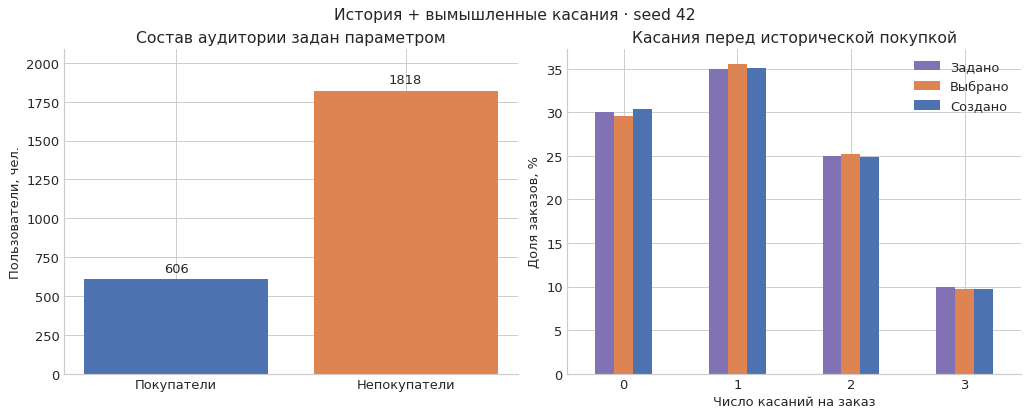

,Задано,Выбрано,Создано
0,30.0,29.62,30.41
1,35.0,35.51,35.03
2,25.0,25.16,24.84
3,10.0,9.71,9.71


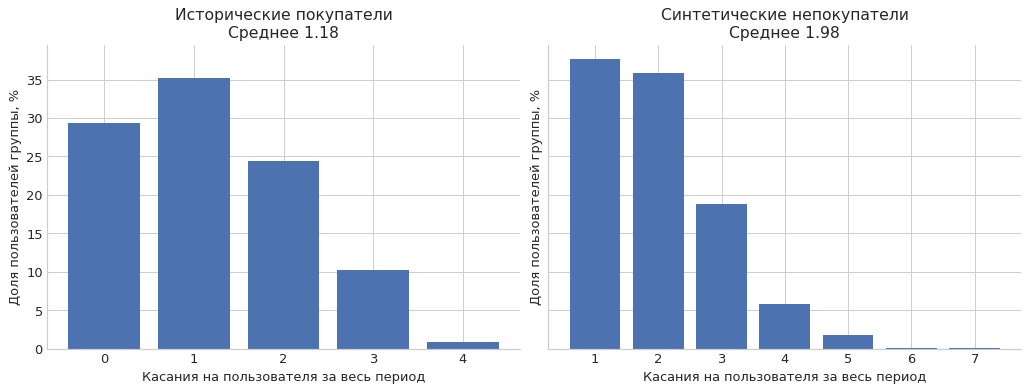

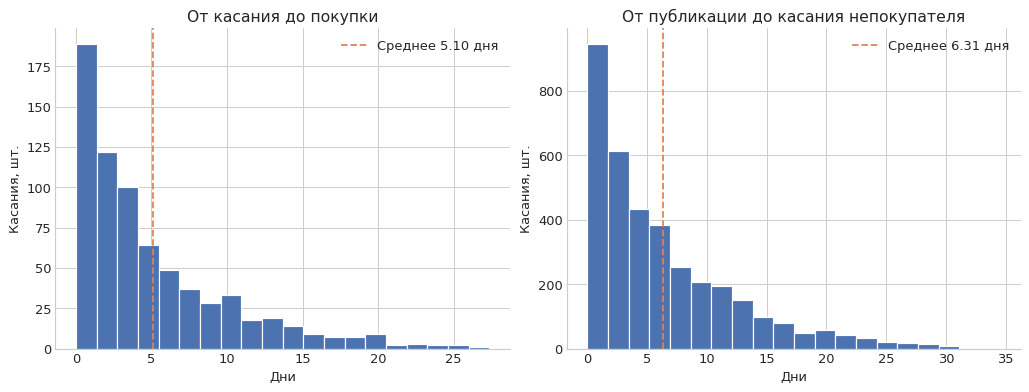

In [6]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'svg.fonttype': 'none'})
BLUE, ORANGE, PURPLE = '#4C72B0', '#DD8452', '#8172B3'

def save_chart(fig, name):
    fig.savefig(OUTPUT / f'{name}.svg', bbox_inches='tight')
    fig.savefig(OUTPUT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()

categories = sorted(set(BUYER_TOUCH_COUNTS) | {0})
distribution = pd.DataFrame(index=categories)
distribution['Задано'] = pd.Series(dict(zip(BUYER_TOUCH_COUNTS, BUYER_TOUCH_PROBABILITIES))).reindex(categories, fill_value=0)*100
for col, label in [('requested_touches', 'Выбрано'), ('actual_touches', 'Создано')]:
    distribution[label] = order_diagnostics[col].value_counts(normalize=True).reindex(categories, fill_value=0)*100
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
bars = axes[0].bar(['Покупатели', 'Непокупатели'], [len(student_ids), n_nonbuyers], color=[BLUE,ORANGE])
axes[0].bar_label(bars, padding=4)
axes[0].set(title='Состав аудитории задан параметром', ylabel='Пользователи, чел.', ylim=(0,max(len(student_ids),n_nonbuyers)*1.15))
distribution.plot.bar(ax=axes[1], color=[PURPLE, ORANGE, BLUE], rot=0)
axes[1].set(title='Касания перед исторической покупкой', xlabel='Число касаний на заказ', ylabel='Доля заказов, %')
fig.suptitle(f'История + вымышленные касания · seed {SEED}')
save_chart(fig, '01_population_and_order_touches')
display(distribution.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout='constrained')
for ax, group, label in zip(axes, ['buyer','nonbuyer'], ['Исторические покупатели','Синтетические непокупатели']):
    values=users.loc[users.user_group.eq(group), 'touches']
    frequencies=values.value_counts().sort_index()
    ax.bar(frequencies.index, frequencies/max(len(values),1)*100, color=BLUE)
    ax.set(title=f'{label}\nСреднее {values.mean():.2f}', xlabel='Касания на пользователя за весь период', ylabel='Доля пользователей группы, %')
save_chart(fig, '02_user_touches')

buyer_delays = (buyer_touches.timestamp_order-buyer_touches.timestamp_touch).dt.total_seconds()/86400
nonbuyer_touches = touches_with_post_time.loc[touches_with_post_time.user_group.eq('nonbuyer')]
nonbuyer_delays = (nonbuyer_touches.timestamp-nonbuyer_touches.publication_time).dt.total_seconds()/86400
fig, axes = plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for ax, values, title in zip(axes, [buyer_delays,nonbuyer_delays], ['От касания до покупки', 'От публикации до касания непокупателя']):
    ax.hist(values,bins=20,color=BLUE,edgecolor='white')
    if len(values):
        ax.axvline(values.mean(),color=ORANGE,linestyle='--',label=f'Среднее {values.mean():.2f} дня')
        ax.legend()
    ax.set(title=title,xlabel='Дни',ylabel='Касания, шт.')
save_chart(fig,'03_delays')

## Курсы и календарь

Все курсы сохранены. На графике количества продаж считаются позиции заказа: покупка двух курсов даёт две позиции и один заказ. Выручка по курсам берётся из исходных сумм позиций. Акция не выводится из наличия нескольких курсов.

Календарь показывает исторические покупки и вымышленные события. Сходство их динамики частично создаётся генерацией касаний перед известными покупками.

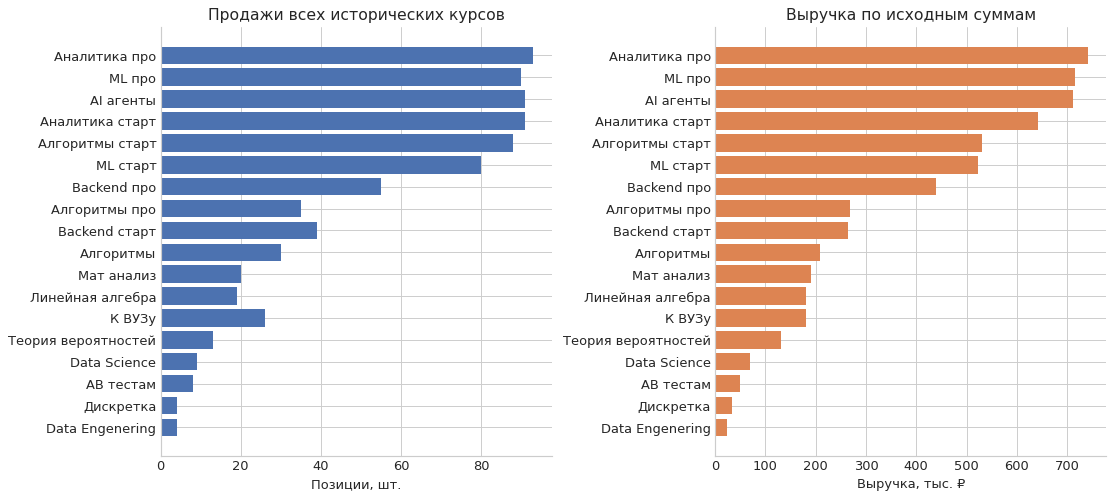

,items,revenue
course,,
Data Engenering,4,24845.00
Дискретка,4,34415.00
АВ тестам,8,49610.00
Data Science,9,69295.00
Теория вероятностей,13,132107.50
К ВУЗу,26,180250.00
Линейная алгебра,19,180665.00
Мат анализ,20,191382.50
Алгоритмы,30,209482.50


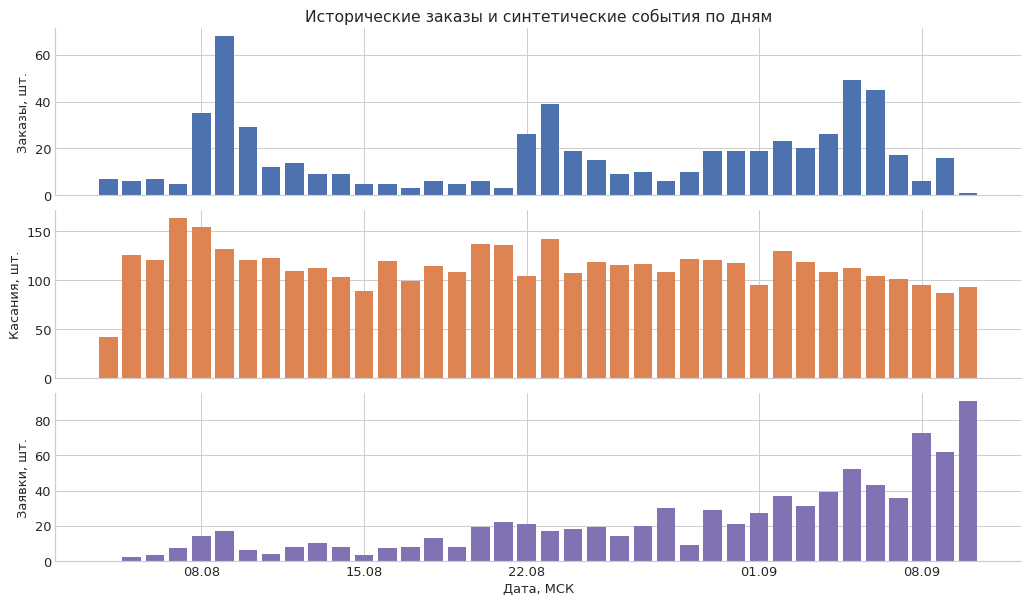

In [7]:
products = items.groupby('course').agg(items=('item_id','size'), revenue=('amount','sum')).sort_values('revenue')
fig, axes=plt.subplots(1,2,figsize=(13,max(5,len(products)*.32)),layout='constrained')
axes[0].barh(products.index,products['items'],color=BLUE)
axes[0].set(title='Продажи всех исторических курсов',xlabel='Позиции, шт.')
axes[1].barh(products.index,products.revenue/1000,color=ORANGE)
axes[1].set(title='Выручка по исходным суммам',xlabel='Выручка, тыс. ₽')
save_chart(fig,'04_products')
display(products)

calendar=pd.date_range(observation_start,observation_end-pd.Timedelta(days=1),freq='D')
daily=pd.DataFrame(index=calendar)
daily['Заказы']=orders.groupby(orders.timestamp.dt.normalize()).size().reindex(calendar,fill_value=0)
daily['Касания']=touches.groupby(touches.timestamp.dt.normalize()).size().reindex(calendar,fill_value=0)
daily['Заявки']=leads.groupby(leads.timestamp.dt.normalize()).size().reindex(calendar,fill_value=0)
fig,axes=plt.subplots(3,1,figsize=(12,7),sharex=True,layout='constrained')
for ax,(column,color) in zip(axes,zip(daily.columns,[BLUE,ORANGE,PURPLE])):
    ax.bar(daily.index,daily[column],color=color)
    ax.set(ylabel=f'{column}, шт.')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m',tz=TIMEZONE))
axes[0].set_title('Исторические заказы и синтетические события по дням')
axes[-1].set_xlabel('Дата, МСК')
save_chart(fig,'05_calendar')

## Исторические продажи и анонсы: проверка текстов

Здесь используются **только исторические покупки и публикации**, без сгенерированных касаний. В общем графике — заказы (студент + точное время); в графиках курсов — позиции заказов. Один заказ с двумя курсами учитывается один раз в общем графике и по одному разу в соответствующих курсах. Нули обозначают отсутствие записей в доступной выгрузке, не доказательство полноты истории.

Ручная проверка обнаружила ограничения существующей разметки: пост 1859 от 22 августа анонсирует пять направлений ПРО, хотя поле product содержит только «Аналитика про»; посты 1870, 1872, 1875, 1877, 1878, 1880 о текущих отборах на стажировки имеют категорию regular. Категория event_announcement объединяет приглашения на собственную бесплатную неделю, а не внешние календарные события.

Ниже — отдельные аналитические пометки по текстам, без изменения исходных категорий. Дата публикации не обязательно совпадает с датой открытия отбора. Дедлайн Т-Банка 6 сентября указан в постах; дата независимо не проверялась. Неделя «Аналитика вне SQL» не сопоставляется автоматически с платным курсом. Тематическое сходство не доказывает связь продукта.

Сопоставление по дням не показывает, была ли покупка раньше поста в тот же день. Поэтому дополнительно считаем покупки до/после **точного времени** публикации 1859. Наличие покупок ПРО до анонса означает, что его нельзя считать началом доступности этих продуктов.


Пики заказов: 2026-08-09 00:00:00+03:00    68
2026-09-05 00:00:00+03:00    49
2026-09-06 00:00:00+03:00    45
2026-08-23 00:00:00+03:00    39
2026-08-08 00:00:00+03:00    35


,post_id,publication_time,plot_group,original_category,original_product
0,1836,2026-08-09 13:32:11+03:00,Скидки СТАРТ,discount,NaN
1,1837,2026-08-09 18:35:40+03:00,Скидки СТАРТ,discount,Алгоритмы
2,1838,2026-08-10 16:26:59+03:00,Скидки СТАРТ,discount,NaN
3,1840,2026-08-10 20:33:06+03:00,Скидки СТАРТ,discount,NaN
4,1859,2026-08-22 13:19:48+03:00,Анонс линейки ПРО,course_launch,Аналитика про
5,1870,2026-08-28 19:05:59+03:00,Отборы: Т-Банк / Яндекс,regular,NaN
6,1872,2026-08-29 21:58:58+03:00,Отборы: Т-Банк / Яндекс,regular,Аналитика про
7,1875,2026-08-31 17:11:02+03:00,Отборы: Т-Банк / Яндекс,regular,NaN
8,1876,2026-09-01 20:40:56+03:00,Отборы: Т-Банк / Яндекс,regular,NaN
9,1877,2026-09-02 19:06:05+03:00,Отборы: Т-Банк / Яндекс,regular,NaN


,Курс,До поста (вся доступная история),После поста (вся доступная история)
0,Аналитика про,13,80
1,ML про,8,82
2,Backend про,11,44
3,Алгоритмы про,3,32
4,AI агенты,2,89


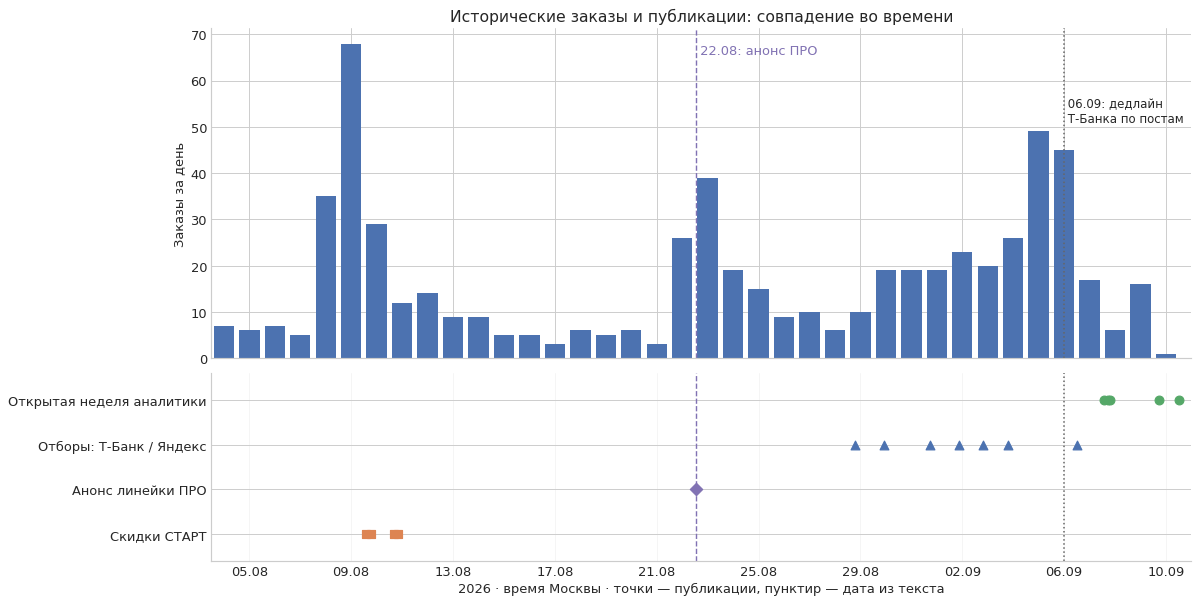

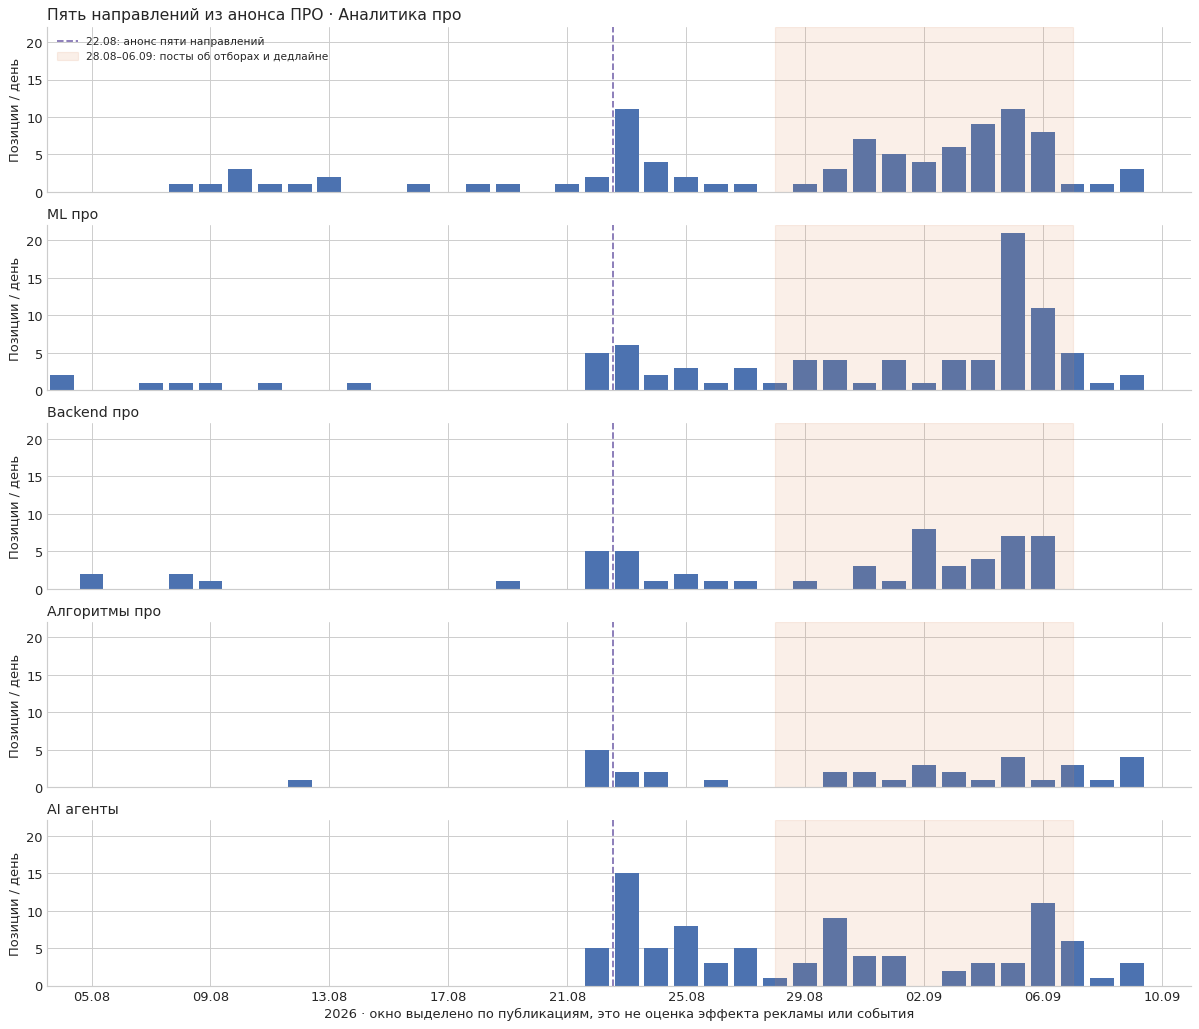

In [8]:
# Явные аналитические группы публикаций; исходная классификация не меняется.
PRO_COURSES = ['Аналитика про', 'ML про', 'Backend про', 'Алгоритмы про', 'AI агенты']
ANNOUNCEMENT_GROUPS = {
    'Скидки СТАРТ': [1836, 1837, 1838, 1840],
    'Анонс линейки ПРО': [1859],
    'Отборы: Т-Банк / Яндекс': [1870, 1872, 1875, 1876, 1877, 1878, 1880],
    'Открытая неделя аналитики': [1887, 1892, 1893, 1897, 1898],
}
assert set(PRO_COURSES) <= set(sales.course.unique())
post_lookup = posts.set_index('post_id')
assert post_lookup.index.is_unique
review_rows = []
for group, ids in ANNOUNCEMENT_GROUPS.items():
    assert set(ids) <= set(post_lookup.index)
    for post_id in ids:
        r = post_lookup.loc[post_id]
        review_rows.append({'post_id': post_id, 'publication_time': r.publication_time,
                           'plot_group': group, 'original_category': r.post_type,
                           'original_product': r['product'], 'text': r.post_text})
announcement_review = pd.DataFrame(review_rows).sort_values('publication_time')
display(announcement_review.drop(columns='text'))
announcement_review.to_csv(OUTPUT / '06_announcement_review.csv', index=False)
# Границы календаря совпадают с доступной историей покупок.
calendar = pd.date_range(observation_start, observation_end, inclusive='left', freq='D')
order_daily = orders.groupby(orders.timestamp.dt.normalize()).size().reindex(calendar, fill_value=0)
course_daily = pd.DataFrame({course: sales.loc[sales.course.eq(course)].groupby(
    sales.loc[sales.course.eq(course), 'timestamp'].dt.normalize()).size().reindex(calendar, fill_value=0)
    for course in PRO_COURSES})
assert order_daily.sum() == len(orders)
assert course_daily.to_numpy().sum() == sales.course.isin(PRO_COURSES).sum()
launch_time = post_lookup.loc[1859, 'publication_time']
launch_counts = pd.DataFrame({
    'Курс': PRO_COURSES,
    'До поста (вся доступная история)': [int((sales.course.eq(c) & sales.timestamp.lt(launch_time)).sum()) for c in PRO_COURSES],
    'После поста (вся доступная история)': [int((sales.course.eq(c) & sales.timestamp.ge(launch_time)).sum()) for c in PRO_COURSES],
})
display(launch_counts)
launch_counts.to_csv(OUTPUT / '07_launch_counts.csv', index=False)
order_daily.rename('orders').to_csv(OUTPUT / '06_historical_orders_daily.csv', index_label='date')
course_daily.to_csv(OUTPUT / '07_pro_courses_daily.csv', index_label='date')

colors = ['#DD8452', '#8172B3', '#4C72B0', '#55A868']
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1.7]}, layout='constrained')
axes[0].bar(calendar, order_daily, width=.8, color='#4C72B0')
axes[0].set(title='Исторические заказы и публикации: совпадение во времени', ylabel='Заказы за день')
for y, ((group, ids), color) in enumerate(zip(ANNOUNCEMENT_GROUPS.items(), colors)):
    times = post_lookup.loc[ids, 'publication_time']
    axes[1].scatter(times, [y]*len(times), color=color, s=55, marker=['s','D','^','o'][y])
axes[1].set_yticks(range(4), list(ANNOUNCEMENT_GROUPS))
axes[1].set_ylim(-.6, 3.6)
axes[1].grid(axis='x', alpha=.2)
for ax in axes:
    ax.axvline(launch_time, color=colors[1], ls='--', lw=1.2)
    ax.axvline(pd.Timestamp('2026-09-06', tz=TIMEZONE), color='#666666', ls=':', lw=1.3)
    ax.set_xlim(calendar[0]-pd.Timedelta(hours=12), observation_end)
axes[0].text(launch_time, axes[0].get_ylim()[1]*.95, ' 22.08: анонс ПРО', color=colors[1], va='top')
axes[0].text(pd.Timestamp('2026-09-06', tz=TIMEZONE), axes[0].get_ylim()[1]*.79,
             ' 06.09: дедлайн\n Т-Банка по постам', fontsize=10, va='top')
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=4, tz=TIMEZONE))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d.%m', tz=TIMEZONE))
axes[1].set_xlabel('2026 · время Москвы · точки — публикации, пунктир — дата из текста')
save_chart(fig, '06_historical_announcements')

fig, axes = plt.subplots(5, 1, figsize=(14, 12), sharex=True, sharey=True, layout='constrained')
for ax, course in zip(axes, PRO_COURSES):
    ax.bar(calendar, course_daily[course], color='#4C72B0', width=.8)
    ax.axvline(launch_time, color='#8172B3', ls='--', label='22.08: анонс пяти направлений')
    ax.axvspan(pd.Timestamp('2026-08-28', tz=TIMEZONE), pd.Timestamp('2026-09-07', tz=TIMEZONE),
               color='#DD8452', alpha=.13, label='28.08–06.09: посты об отборах и дедлайне')
    ax.set_title(course, loc='left', fontsize=12)
    ax.set_ylabel('Позиции / день')
    ax.set_xlim(calendar[0]-pd.Timedelta(hours=12), observation_end)
axes[0].legend(loc='upper left', fontsize=9)
axes[0].set_title('Пять направлений из анонса ПРО · Аналитика про', loc='left')
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=4, tz=TIMEZONE))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d.%m', tz=TIMEZONE))
axes[-1].set_xlabel('2026 · окно выделено по публикациям, это не оценка эффекта рекламы или события')
save_chart(fig, '07_pro_courses_announcements')
print('Пики заказов:', order_daily.sort_values(ascending=False).head(5).to_string())


### Что можно заключить

Графики показывают временные совпадения, а не причинный эффект. Анонс ПРО относится сразу к пяти продуктам; продажи этих продуктов встречаются и до него. Сообщения об отборах совмещают внешние новости с предложением купить курс — приписать последующий рост только «естественному спросу» или только рекламе нельзя. После начала открытой недели 7 сентября доступно лишь несколько дней, поэтому длинный отклик не наблюдается.

Текущий движок `src/core/attribution.py::compute` не использует категорию поста, продукт или календарь: только пользователя, время касаний, окно и предыдущую покупку. Категория присоединяется в отчёте как описание. В этой генерации посты выбираются с угасанием внимания по возрасту, но без весов по категориям и без соответствия покупаемому курсу. Эти графики не проверяют причинную точность атрибуции и не служат основанием для автоматического вычитания «органики».


## Экспорт

CSV сохраняются в папку OUTPUT_SUBDIR. Файл manifest.json содержит параметры, происхождение таблиц и хеши исходных файлов. При новом запуске эти результаты перезаписываются. Для сохранения альтернативного предположения измените OUTPUT_SUBDIR.

Покупки и публикации имеют историческое происхождение, касания и заявки — синтетическое. Весь набор является экспериментальным. Эти признаки нельзя использовать как доказательство реальной воронки или эффекта рекламы.

In [9]:
tables={'users':users,'orders':orders,'order_items':items,'placements':posts.drop(columns=['post_text']),
        'touches':touches,'leads':leads,'order_diagnostics':order_diagnostics}
for name,frame in tables.items():
    frame.to_csv(OUTPUT / f'{name}.csv',index=False)
summary.to_csv(OUTPUT / 'summary.csv',header=['value'])
distribution.to_csv(OUTPUT / 'touch_distribution.csv',index_label='touches_per_order')
products.to_csv(OUTPUT / 'products.csv')
daily.to_csv(OUTPUT / 'daily.csv',index_label='date')
parameter_names=['SEED','BUYER_TOUCH_COUNTS','BUYER_TOUCH_PROBABILITIES','ATTRIBUTION_WINDOW_DAYS',
                 'BUYER_DELAY_SCALE_DAYS','NONBUYERS_PER_BUYER','NONBUYER_EXTRA_TOUCHES_LAMBDA',
                 'POST_ATTENTION_HALF_LIFE_DAYS','NONBUYER_TIME_DISTRIBUTION','LEAD_PROBABILITY','TIMEZONE','MIN_GAP_SECONDS','OUTPUT_SUBDIR']
manifest={'experiment_only':True, 'contract_version':CONTRACT_VERSION,
          'as_of':pd.Timestamp.now(tz=TIMEZONE).isoformat(), 'scope':'current_generation_only',
          'analysis_units':['user','order','order_item','touch','lead','placement'],
          'placement_ids':posts.placement_id.tolist(), 'attribution_model':None,
          'parameters':{name:globals()[name] for name in parameter_names},
          'sources':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in [sales_path,posts_path]},
          'observation_start':str(observation_start),'observation_end_exclusive':str(observation_end),
          'checks':'passed','historical_order_count':len(orders),'historical_revenue_cents':int(orders.amount_cents.sum()),
          'provenance':'Purchases and publications from history; touches, leads and nonbuyers simulated',
          'software':{'numpy':np.__version__,'pandas':pd.__version__}}
(OUTPUT / 'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+'\n')
print(f'Данные и графики сохранены в {OUTPUT.relative_to(ROOT)}')

Данные и графики сохранены в outputs/experiments/history_enrichment
